# 📊 DATA VISUALIZATION – SMART FARMING IoT
  
**Nama:** Kosmas Anyeq Beraan  
**NIM:** 2418057  
**Dataset:** Smart Farming Crop Yield 2024 (hasil Data Cleansing)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab

> Tujuan: menggambarkan distribusi kondisi pertanian dan mengeksplorasi hubungan faktor lingkungan, input pertanian, dan hasil panen. Analisis bersifat deskriptif; hubungan dalam grafik **bukan** bukti sebab-akibat.


## 1. Import Library

In [2]:
import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

print("Library berhasil diimport.")

Library berhasil diimport.


## 2. Menghubungkan Google Drive

Jalankan cell ini dan izinkan akses Google Drive bila diminta. File hasil cleansing sebelumnya berada di folder `2418057_Dataset`.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Membaca Dataset



In [4]:
from google.colab import files

nama_file = "Smart_Farming_Crop_Yield_2024_Cleansed.csv"
file_path = f"/content/drive/MyDrive/2418057_Dataset/{nama_file}"

if not os.path.exists(file_path):
    ditemukan = None
    for root, dirs, filenames in os.walk('/content/drive/MyDrive'):
        if nama_file in filenames:
            ditemukan = os.path.join(root, nama_file)
            break
    if ditemukan:
        file_path = ditemukan
    else:
        print("File belum ditemukan di Google Drive. Silakan upload file CSV hasil cleansing.")
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("Dataset belum tersedia. Upload file CSV, lalu jalankan kembali cell.")
        file_path = next(iter(uploaded.keys()))

df = pd.read_csv(file_path)
print("Nama file:", os.path.basename(file_path))
print("Ukuran dataset:", df.shape)
display(df.head())

Nama file: Smart_Farming_Crop_Yield_2024_Cleansed.csv
Ukuran dataset: (500, 22)


,farm_id,region,crop_type,soil_moisture_%,soil_pH,temperature_C,rainfall_mm,humidity_%,sunlight_hours,irrigation_type,...,sowing_date,harvest_date,total_days,yield_kg_per_hectare,sensor_id,timestamp,latitude,longitude,NDVI_index,crop_disease_status
0,FARM0001,North India,Wheat,35.95,5.99,17.79,75.62,77.03,7.27,Unknown,...,2024-01-08,2024-05-09,122,4408.07,SENS0001,2024-03-19,14.970941,82.997689,0.63,Mild
1,FARM0002,South USA,Soybean,19.74,7.24,30.18,89.91,61.13,5.67,Sprinkler,...,2024-02-04,2024-05-26,112,5389.98,SENS0002,2024-04-21,16.613022,70.869009,0.58,Unknown
2,FARM0003,South USA,Wheat,29.32,7.16,27.37,265.43,68.87,8.23,Drip,...,2024-02-03,2024-06-26,144,2931.16,SENS0003,2024-02-28,19.503156,79.068206,0.80,Mild
3,FARM0004,Central USA,Maize,17.33,6.03,33.73,212.01,70.46,5.03,Sprinkler,...,2024-02-21,2024-07-04,134,4227.80,SENS0004,2024-05-14,31.071298,85.519998,0.44,Unknown
4,FARM0005,Central USA,Cotton,19.37,5.92,33.86,269.09,55.73,7.93,Unknown,...,2024-02-05,2024-05-20,105,4979.96,SENS0005,2024-04-13,16.568540,81.691720,0.84,Severe


## 4. Eksplorasi dan Validasi Dataset



In [5]:
kolom_wajib = [
    'crop_type', 'region', 'yield_kg_per_hectare', 'irrigation_type',
    'fertilizer_type', 'temperature_C', 'NDVI_index',
    'soil_moisture_%', 'soil_pH', 'rainfall_mm', 'humidity_%',
    'sunlight_hours', 'pesticide_usage_ml', 'total_days'
]
kolom_hilang = [kol for kol in kolom_wajib if kol not in df.columns]
if kolom_hilang:
    raise ValueError(f"Kolom dataset yang dibutuhkan tidak ada: {kolom_hilang}")
if len(df) < 100:
    raise ValueError(f"Dataset hanya memiliki {len(df)} baris. Syarat minimal 100 baris.")

# Pertahankan kategori Unknown sebagai kategori tersendiri agar tidak menyembunyikan informasi.
for kol in ['crop_type', 'region', 'irrigation_type', 'fertilizer_type']:
    df[kol] = df[kol].fillna('Unknown').astype(str).str.strip().replace('', 'Unknown')

kolom_numerik = ['yield_kg_per_hectare', 'temperature_C', 'NDVI_index',
                 'soil_moisture_%', 'soil_pH', 'rainfall_mm', 'humidity_%',
                 'sunlight_hours', 'pesticide_usage_ml', 'total_days']
for kol in kolom_numerik:
    df[kol] = pd.to_numeric(df[kol], errors='coerce')

print(f"Jumlah baris: {len(df)}")
print(f"Jumlah kolom: {len(df.columns)}")
print(f"Total missing value: {int(df.isna().sum().sum())}")
print(f"Total duplikat: {int(df.duplicated().sum())}")
print("\nRingkasan kolom utama:")
display(df[kolom_wajib].describe(include='all').transpose().round(2))

Jumlah baris: 500
Jumlah kolom: 22
Total missing value: 0
Total duplikat: 0

Ringkasan kolom utama:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
crop_type,500,5,Maize,111,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,500,5,Central USA,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yield_kg_per_hectare,500.0,NaN,NaN,NaN,4032.92694,1174.43304,2023.56,2994.82,4071.69,5062.11,5998.29
irrigation_type,500,4,Unknown,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fertilizer_type,500,3,Inorganic,167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_C,500.0,NaN,NaN,NaN,24.67574,5.348899,15.0,20.295,24.655,29.09,34.84
NDVI_index,500.0,NaN,NaN,NaN,0.60206,0.175402,0.3,0.4475,0.61,0.75,0.9
soil_moisture_%,500.0,NaN,NaN,NaN,26.75014,10.150053,10.16,17.89,25.855,36.0225,44.98
soil_pH,500.0,NaN,NaN,NaN,6.52398,0.585558,5.51,6.03,6.53,7.04,7.5
rainfall_mm,500.0,NaN,NaN,NaN,181.68574,72.293091,50.17,119.2175,191.545,239.035,298.96


## 5. Pengaturan Tampilan Grafik


In [6]:
NAVY = '#183153'
TEAL = '#159895'
GOLD = '#E6AF41'
LIGHT = '#EAF3F5'
BLUE = '#4778A9'
INK = '#243347'
PALETTE = [TEAL, BLUE, GOLD, '#845EC2', '#E67B67', '#53A67A', '#7B8DA3']

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.titlecolor': NAVY, 'axes.labelcolor': INK,
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.edgecolor': '#D6E0E6', 'grid.color': '#E2EAF0',
    'grid.alpha': 0.65, 'figure.dpi': 110,
    'savefig.facecolor': 'white', 'font.family': 'DejaVu Sans'
})

folder_grafik = Path('/content/DataVisualization2418057_Grafik')
folder_grafik.mkdir(parents=True, exist_ok=True)


def akhir_grafik(fig, filename):
    fig.tight_layout(pad=2)
    fig.savefig(folder_grafik / filename, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def grafik_jumlah(kol, judul, nama_file):
    jumlah = df[kol].value_counts().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(11, max(5, 0.65 * len(jumlah) + 2)))
    warna = [PALETTE[i % len(PALETTE)] for i in range(len(jumlah))]
    bars = ax.barh(jumlah.index, jumlah.values, color=warna, height=.65)
    ax.bar_label(bars, padding=7, fmt='%.0f', fontsize=10, fontweight='bold', color=NAVY)
    ax.set_xlim(0, jumlah.max() * 1.19 if len(jumlah) else 1)
    ax.set_xlabel('Jumlah data (baris)')
    ax.set_ylabel('')
    ax.set_title(judul, fontsize=17, fontweight='bold', loc='left', pad=20)
    ax.grid(axis='x', alpha=.35)
    ax.grid(axis='y', visible=False)
    sns.despine(ax=ax, left=True, bottom=True)
    akhir_grafik(fig, nama_file)
    return jumlah


def grafik_rata(kol, judul, nama_file):
    ringkas = (df.groupby(kol, dropna=False)['yield_kg_per_hectare']
                 .agg(rata_rata='mean', jumlah='count')
                 .dropna(subset=['rata_rata'])
                 .sort_values('rata_rata'))
    if ringkas.empty:
        raise ValueError(f"Tidak ada nilai hasil panen valid untuk {kol}.")
    fig, ax = plt.subplots(figsize=(11, max(5, 0.72 * len(ringkas) + 2)))
    bars = ax.barh(ringkas.index, ringkas['rata_rata'], color=TEAL, height=.62)
    for bar, n in zip(bars, ringkas['jumlah']):
        val = bar.get_width()
        ax.text(val + ringkas['rata_rata'].max()*0.016,
                bar.get_y() + bar.get_height()/2,
                f'{val:,.0f}  (n={n})', ha='left', va='center', fontsize=10, color=NAVY)
    ax.set_xlim(0, ringkas['rata_rata'].max() * 1.30)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.set_xlabel('Rata-rata hasil panen (kg/hektare)')
    ax.set_ylabel('')
    ax.set_title(judul, fontsize=17, fontweight='bold', loc='left', pad=20)
    ax.grid(axis='x', alpha=.35)
    ax.grid(axis='y', visible=False)
    sns.despine(ax=ax, left=True, bottom=True)
    akhir_grafik(fig, nama_file)
    return ringkas


def grafik_hubungan(kol, label_x, judul, nama_file):
    valid = df[[kol, 'yield_kg_per_hectare']].dropna()
    fig, ax = plt.subplots(figsize=(11, 6.2))
    sns.regplot(data=valid, x=kol, y='yield_kg_per_hectare', ax=ax,
                scatter_kws={'alpha':.52, 's':44, 'color':TEAL, 'edgecolor':'white'},
                line_kws={'color':GOLD, 'linewidth':2.6}, ci=None)
    r = valid[kol].corr(valid['yield_kg_per_hectare'])
    teks = f'Korelasi Pearson (r): {r:+.2f}' if pd.notna(r) else 'Korelasi tidak dapat dihitung'
    ax.text(.03, .96, teks, transform=ax.transAxes,
            fontsize=11, fontweight='bold', va='top', color=NAVY,
            bbox={'facecolor':LIGHT, 'edgecolor':'none', 'boxstyle':'round,pad=.45'})
    ax.set_xlabel(label_x)
    ax.set_ylabel('Hasil panen (kg/hektare)')
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.set_title(judul, fontsize=17, fontweight='bold', loc='left', pad=18)
    ax.grid(alpha=.35)
    sns.despine(ax=ax)
    akhir_grafik(fig, nama_file)
    return r

print('Tema grafik siap. Folder output:', folder_grafik)

Tema grafik siap. Folder output: /content/DataVisualization2418057_Grafik


## 6. Distribusi Jenis Tanaman – Bar Chart

**Pertanyaan:** Jenis tanaman apa yang paling banyak tercatat dalam dataset?

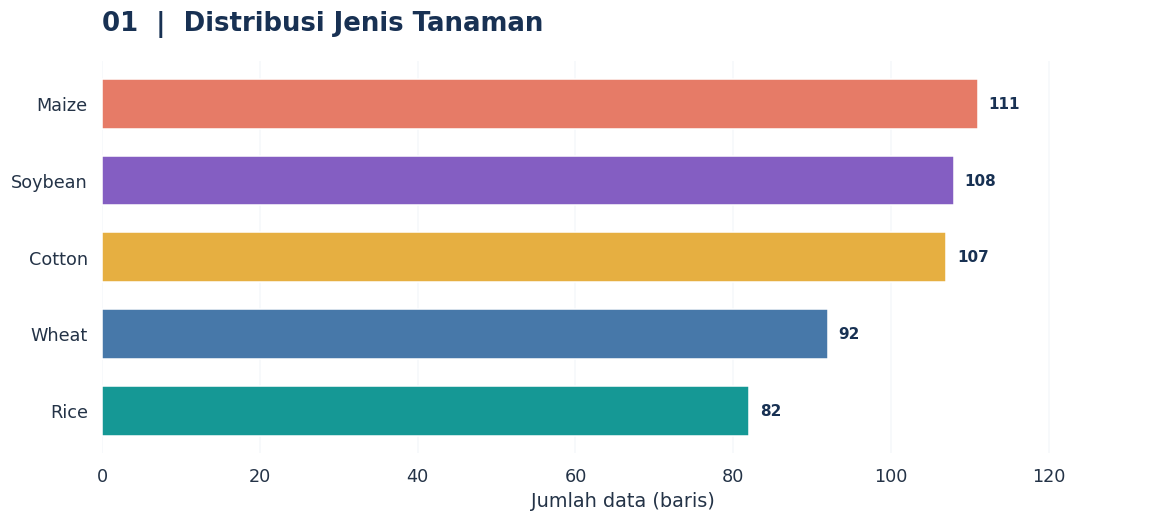

Jenis tanaman paling sering: Maize (111 baris).


In [7]:
jumlah_tanaman = grafik_jumlah(
    'crop_type', '01  |  Distribusi Jenis Tanaman', '01_distribusi_tanaman.png'
)
print(f"Jenis tanaman paling sering: {jumlah_tanaman.idxmax()} ({jumlah_tanaman.max()} baris).")

## 7. Distribusi Wilayah Pertanian – Bar Chart

**Pertanyaan:** Wilayah mana yang paling banyak memiliki catatan pertanian?

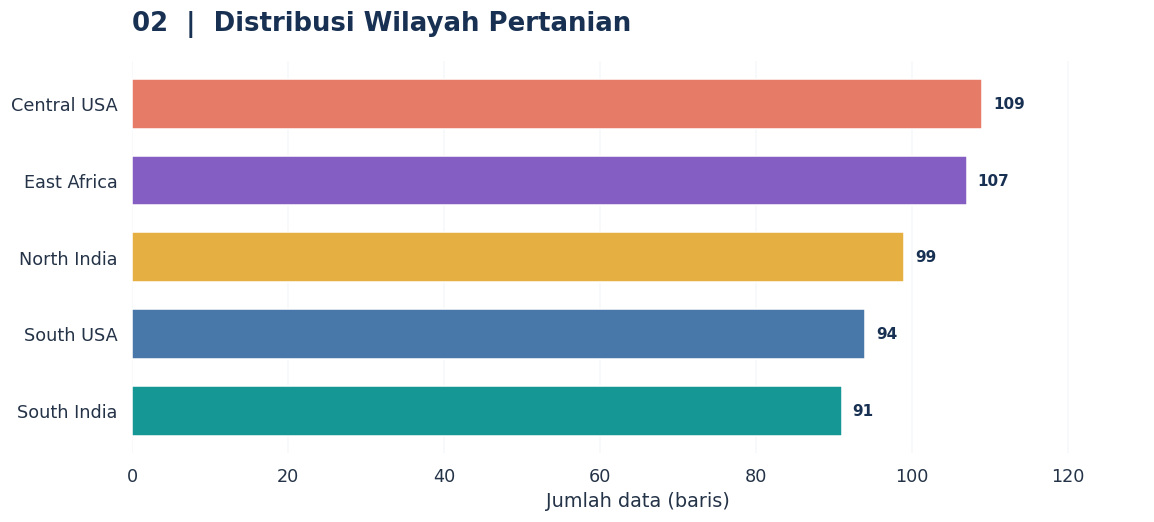

Wilayah dengan catatan terbanyak: Central USA (109 baris).


In [8]:
jumlah_wilayah = grafik_jumlah(
    'region', '02  |  Distribusi Wilayah Pertanian', '02_distribusi_wilayah.png'
)
print(f"Wilayah dengan catatan terbanyak: {jumlah_wilayah.idxmax()} ({jumlah_wilayah.max()} baris).")

## 8. Rata-rata Hasil Panen per Jenis Tanaman – Bar Chart

**Pertanyaan:** Jenis tanaman apa yang memiliki rata-rata hasil panen tertinggi? Perhatikan nilai `n` agar jumlah sampel per kategori terlihat.

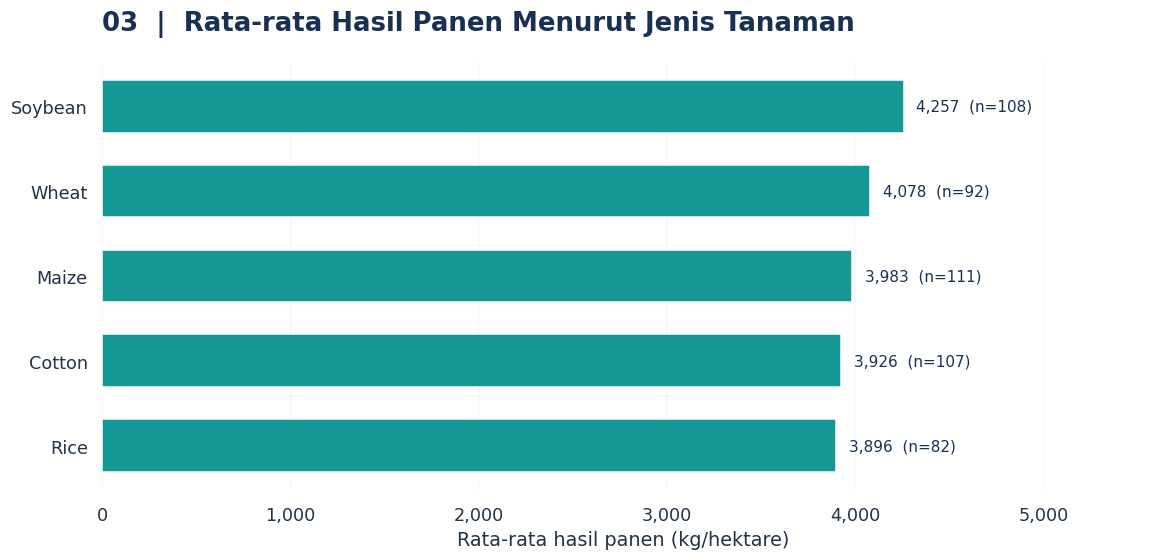

Rata-rata tertinggi: Soybean (4,256.8 kg/hektare).


In [9]:
hasil_per_tanaman = grafik_rata(
    'crop_type', '03  |  Rata-rata Hasil Panen Menurut Jenis Tanaman',
    '03_hasil_panen_jenis_tanaman.png'
)
print(f"Rata-rata tertinggi: {hasil_per_tanaman['rata_rata'].idxmax()} "
      f"({hasil_per_tanaman['rata_rata'].max():,.1f} kg/hektare).")

## 9. Rata-rata Hasil Panen per Wilayah – Bar Chart

**Pertanyaan:** Wilayah mana yang rata-rata hasil panennya tertinggi?

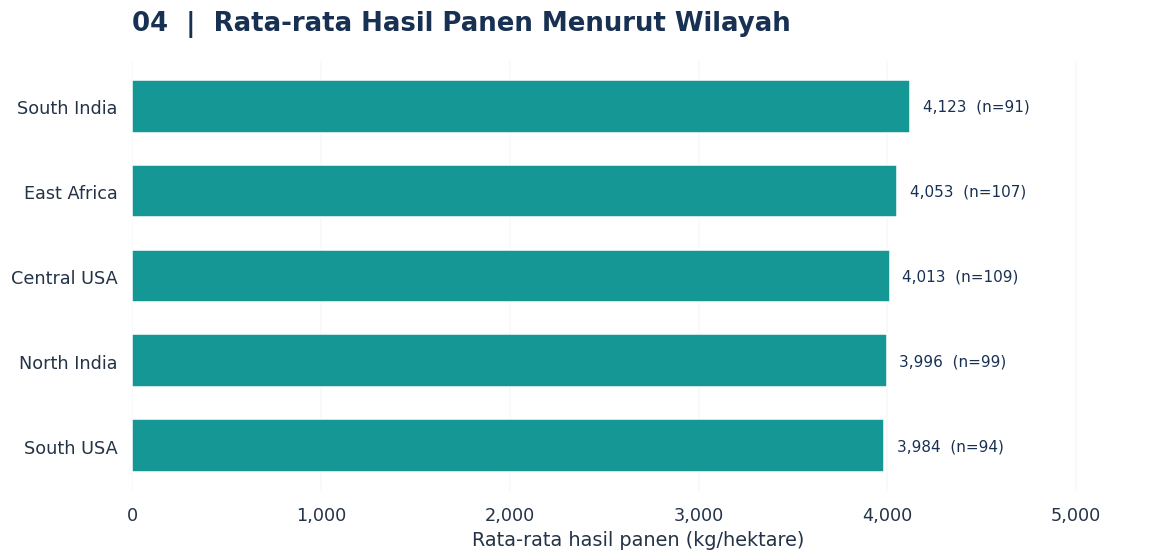

Wilayah rata-rata tertinggi: South India (4,122.9 kg/hektare).


In [10]:
hasil_per_wilayah = grafik_rata(
    'region', '04  |  Rata-rata Hasil Panen Menurut Wilayah',
    '04_hasil_panen_wilayah.png'
)
print(f"Wilayah rata-rata tertinggi: {hasil_per_wilayah['rata_rata'].idxmax()} "
      f"({hasil_per_wilayah['rata_rata'].max():,.1f} kg/hektare).")

## 10. Perbandingan Jenis Irigasi – Bar Chart

**Pertanyaan:** Bagaimana rata-rata hasil panen berbeda menurut jenis irigasi? `Unknown` berarti kategori awal tidak tercatat, **bukan** jenis irigasi.

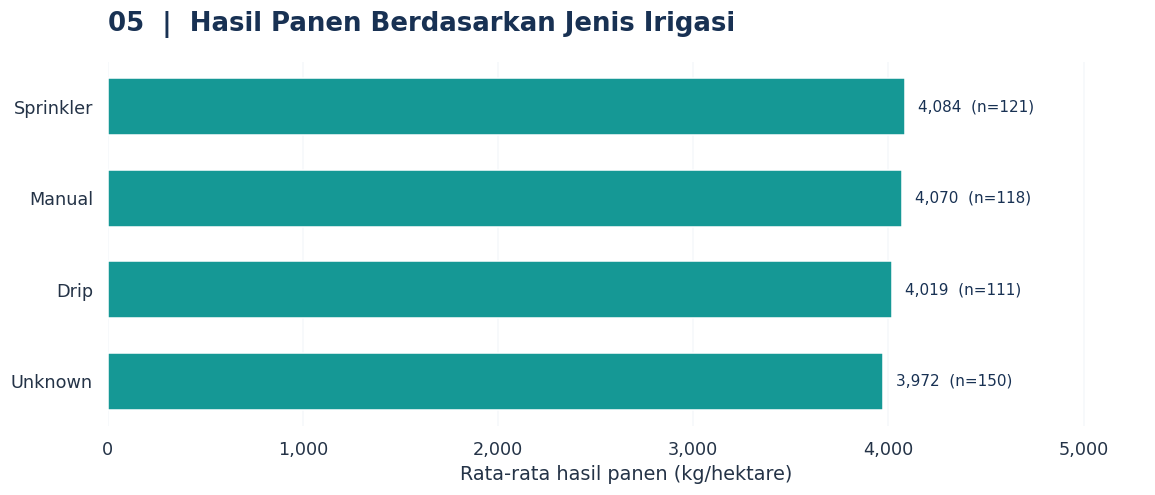

Catatan: perbandingan ini deskriptif, bukan bukti bahwa jenis irigasi menyebabkan hasil lebih tinggi.


,rata_rata,jumlah
irrigation_type,,
Unknown,3972.13,150
Drip,4019.45,111
Manual,4070.09,118
Sprinkler,4084.41,121


In [11]:
hasil_per_irigasi = grafik_rata(
    'irrigation_type', '05  |  Hasil Panen Berdasarkan Jenis Irigasi',
    '05_hasil_panen_irigasi.png'
)
print('Catatan: perbandingan ini deskriptif, bukan bukti bahwa jenis irigasi menyebabkan hasil lebih tinggi.')
display(hasil_per_irigasi.round(2))

## 11. Perbandingan Jenis Pupuk – Bar Chart

**Pertanyaan:** Bagaimana rata-rata hasil panen berbeda berdasarkan kategori pupuk?

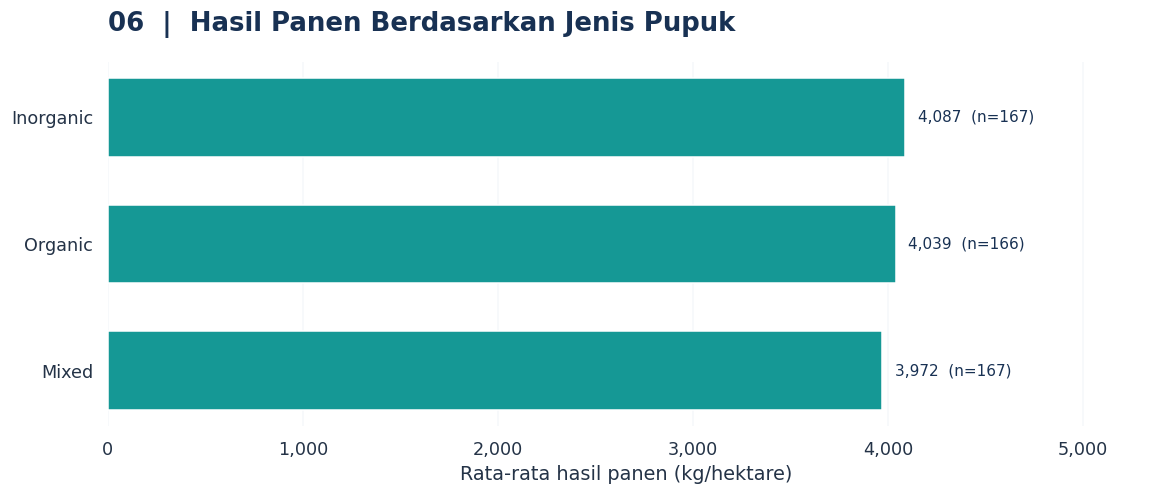

Catatan: jenis tanaman, wilayah, dan kondisi lingkungan juga dapat berhubungan dengan hasil panen.


,rata_rata,jumlah
fertilizer_type,,
Mixed,3972.41,167
Organic,4039.28,166
Inorganic,4087.12,167


In [21]:
hasil_per_pupuk = grafik_rata(
    'fertilizer_type', '06  |  Hasil Panen Berdasarkan Jenis Pupuk',
    '06_hasil_panen_pupuk.png'
)
print('Catatan: jenis tanaman, wilayah, dan kondisi lingkungan juga dapat berhubungan dengan hasil panen.')
display(hasil_per_pupuk.round(2))

## 12. Hubungan Suhu dan Hasil Panen – Scatter Plot

**Pertanyaan:** Apakah suhu lingkungan tampak berhubungan dengan hasil panen? Garis menunjukkan kecenderungan linear, bukan hubungan sebab-akibat.

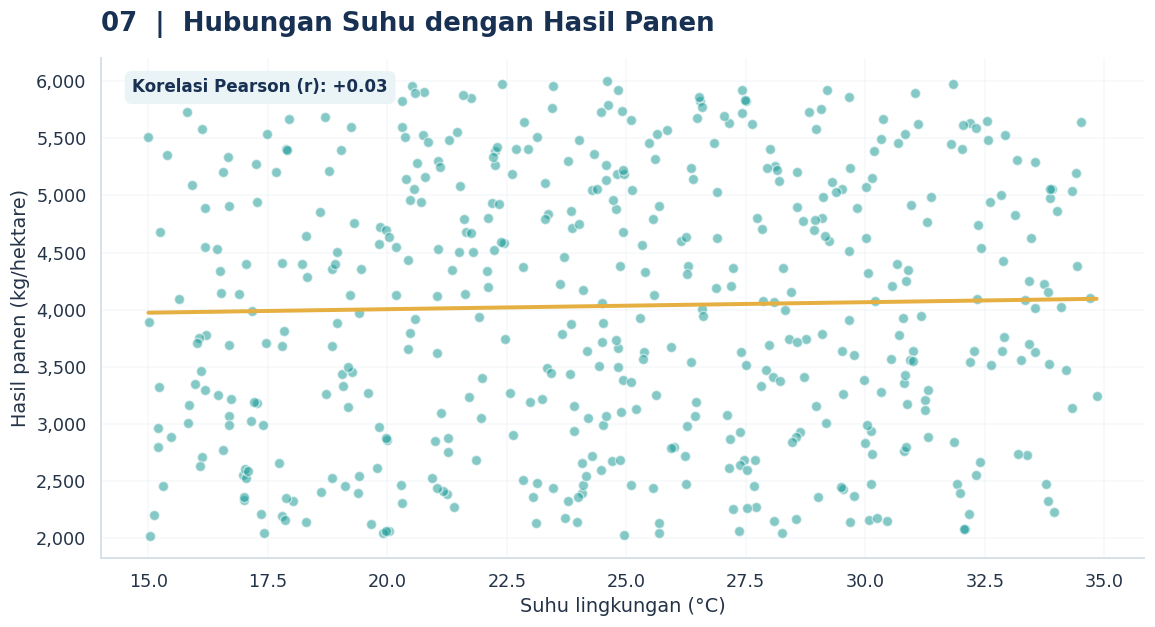

Korelasi Pearson suhu vs hasil panen: 0.028


In [13]:
korelasi_suhu = grafik_hubungan(
    'temperature_C', 'Suhu lingkungan (°C)',
    '07  |  Hubungan Suhu dengan Hasil Panen', '07_suhu_vs_hasil_panen.png'
)
print(f'Korelasi Pearson suhu vs hasil panen: {korelasi_suhu:.3f}')

## 13. Hubungan NDVI dan Hasil Panen – Scatter Plot

**Pertanyaan:** Apakah indeks kehijauan vegetasi (NDVI) berhubungan dengan hasil panen?

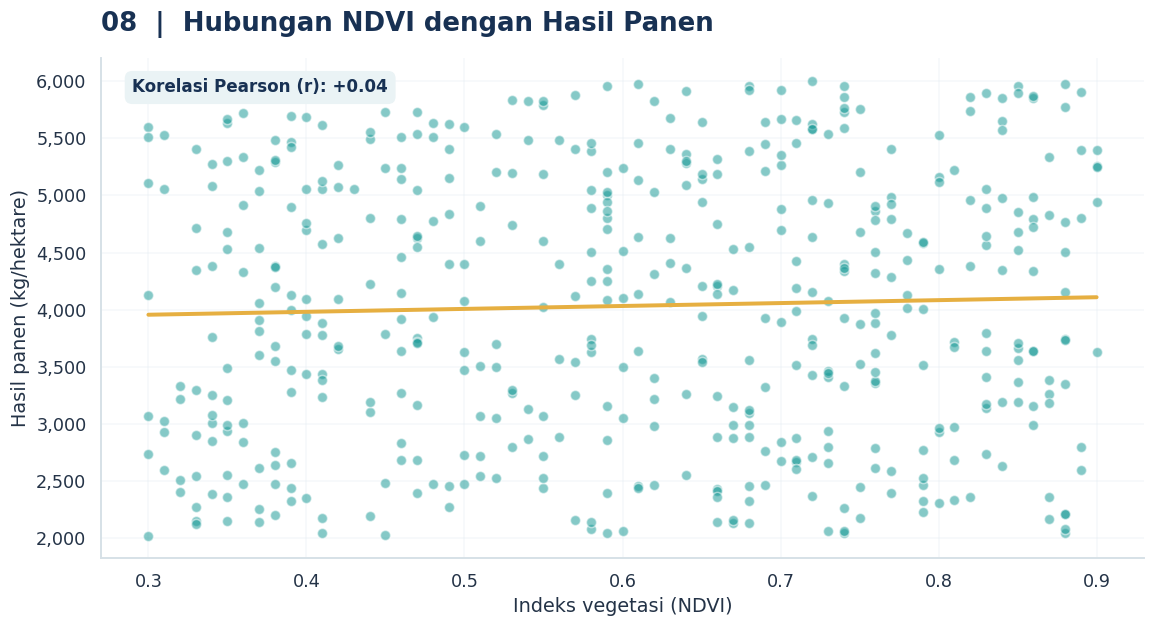

Korelasi Pearson NDVI vs hasil panen: 0.038


In [14]:
korelasi_ndvi = grafik_hubungan(
    'NDVI_index', 'Indeks vegetasi (NDVI)',
    '08  |  Hubungan NDVI dengan Hasil Panen', '08_ndvi_vs_hasil_panen.png'
)
print(f'Korelasi Pearson NDVI vs hasil panen: {korelasi_ndvi:.3f}')

## 14. Variasi Hasil Panen Tiap Tanaman – Box Plot

**Pertanyaan:** Apakah hasil panen cenderung stabil atau memiliki variasi besar dalam setiap jenis tanaman? Garis pada kotak = median; titik di luar whisker = nilai ekstrem menurut aturan box plot (belum tentu salah).

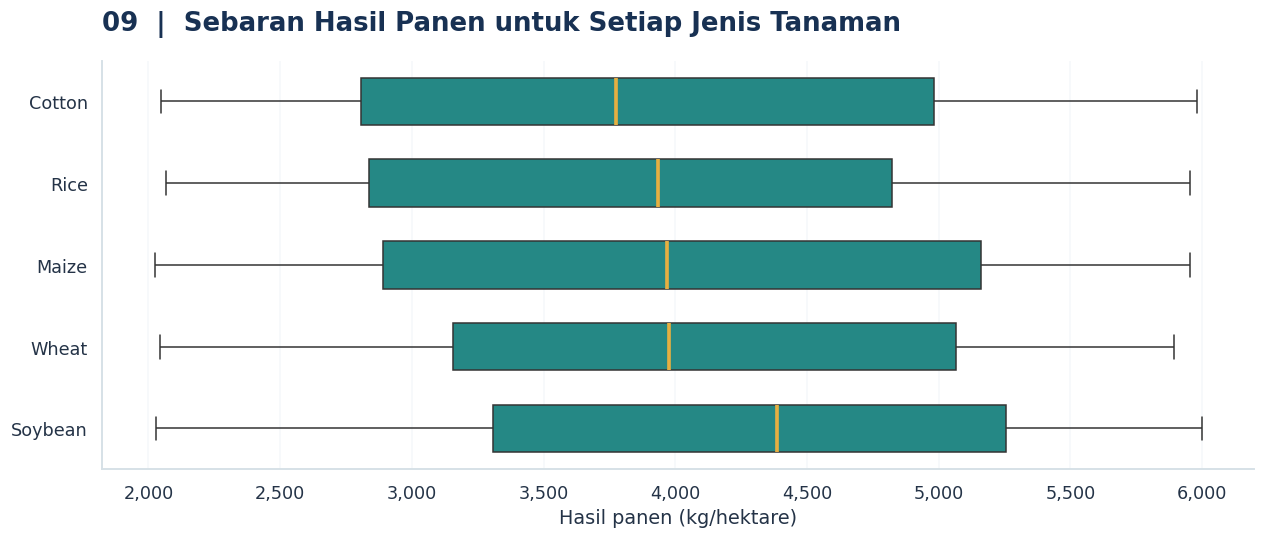

Box plot digunakan untuk membandingkan median, variasi, serta potensi nilai ekstrem.


In [15]:
urutan = (df.groupby('crop_type')['yield_kg_per_hectare']
             .median().sort_values().index.tolist())
fig, ax = plt.subplots(figsize=(12, max(5, .68 * len(urutan) + 2)))
sns.boxplot(data=df, x='yield_kg_per_hectare', y='crop_type',
            order=urutan, color=TEAL, width=.58, fliersize=3.5,
            medianprops={'color':GOLD, 'linewidth':2.4}, ax=ax)
ax.set_title('09  |  Sebaran Hasil Panen untuk Setiap Jenis Tanaman',
             fontsize=17, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('Hasil panen (kg/hektare)')
ax.set_ylabel('')
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='x', alpha=.35)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax)
akhir_grafik(fig, '09_boxplot_hasil_panen.png')
print('Box plot digunakan untuk membandingkan median, variasi, serta potensi nilai ekstrem.')

## 15. Korelasi Variabel Numerik – Heatmap

**Pertanyaan:** Variabel numerik mana yang paling berkorelasi dengan hasil panen? Nilai korelasi berada pada skala −1 hingga +1; korelasi tidak membuktikan penyebab.

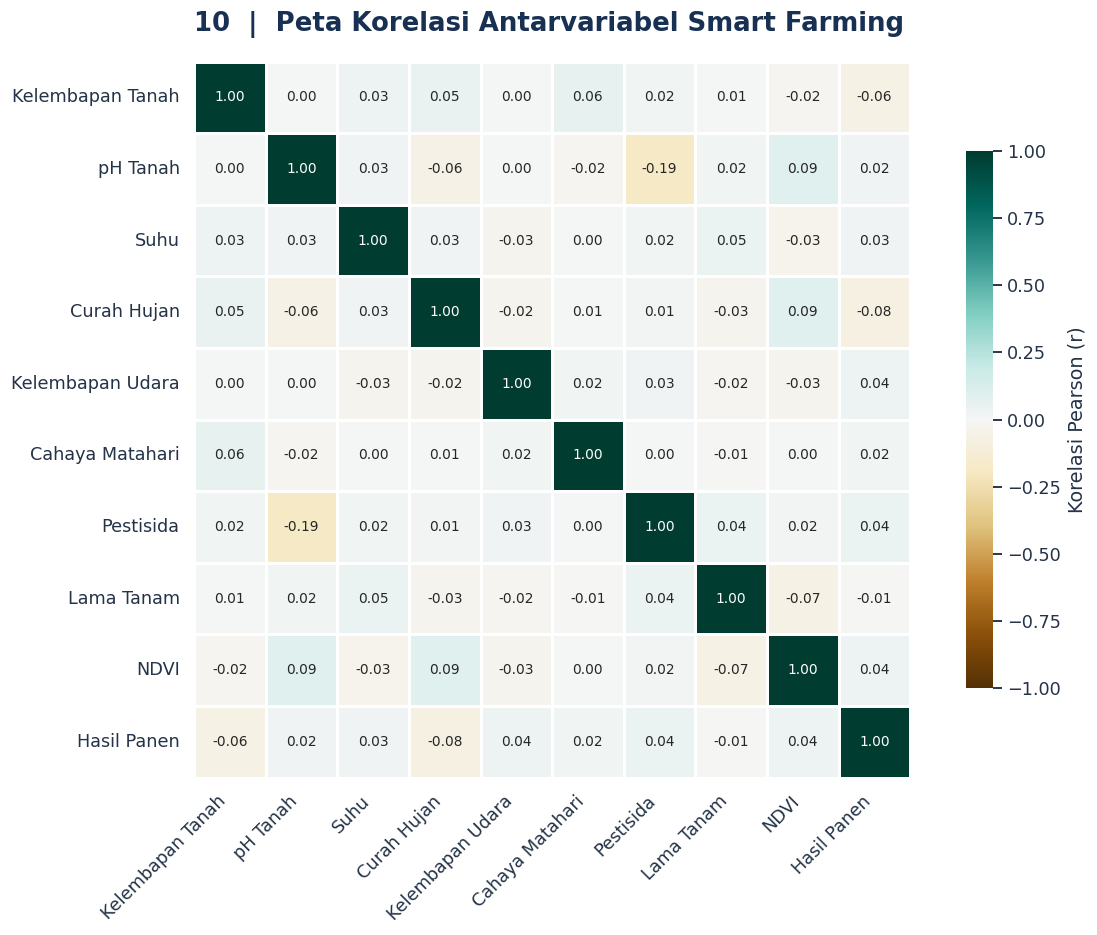

Korelasi linear absolut terkuat terhadap hasil panen: rainfall_mm (r = -0.077)


In [16]:
kolom_heatmap = [
    'soil_moisture_%', 'soil_pH', 'temperature_C', 'rainfall_mm',
    'humidity_%', 'sunlight_hours', 'pesticide_usage_ml',
    'total_days', 'NDVI_index', 'yield_kg_per_hectare'
]
label_heatmap = {
    'soil_moisture_%':'Kelembapan Tanah', 'soil_pH':'pH Tanah',
    'temperature_C':'Suhu', 'rainfall_mm':'Curah Hujan',
    'humidity_%':'Kelembapan Udara', 'sunlight_hours':'Cahaya Matahari',
    'pesticide_usage_ml':'Pestisida', 'total_days':'Lama Tanam',
    'NDVI_index':'NDVI', 'yield_kg_per_hectare':'Hasil Panen'
}
matriks = df[kolom_heatmap].corr(method='pearson')
matriks_berlabel = matriks.rename(index=label_heatmap, columns=label_heatmap)
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(matriks_berlabel, ax=ax, cmap='BrBG', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, linewidths=.7,
            linecolor='white', annot_kws={'fontsize':9},
            cbar_kws={'label':'Korelasi Pearson (r)', 'shrink':.75})
ax.set_title('10  |  Peta Korelasi Antarvariabel Smart Farming',
             fontsize=17, fontweight='bold', pad=20, loc='left')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
akhir_grafik(fig, '10_heatmap_korelasi.png')

kolom_korelasi = matriks['yield_kg_per_hectare'].drop('yield_kg_per_hectare').dropna()
if not kolom_korelasi.empty:
    utama = kolom_korelasi.abs().idxmax()
    print(f'Korelasi linear absolut terkuat terhadap hasil panen: {utama} '
          f'(r = {kolom_korelasi[utama]:+.3f})')
else:
    print('Korelasi tidak dapat dihitung dari kolom numerik yang tersedia.')

## 16. Kesimpulan Analisis

Kesimpulan dihitung otomatis dari data sebenarnya. Jangan menafsirkan grafik perbandingan sebagai bukti hubungan sebab-akibat.

In [17]:
print('RINGKASAN HASIL VISUALISASI SMART FARMING')
print('=' * 58)
print(f'Jumlah observasi      : {len(df):,} baris')
print(f'Jumlah kolom          : {df.shape[1]}')
print(f'Jenis tanaman terbanyak: {jumlah_tanaman.idxmax()} ({jumlah_tanaman.max()} baris)')
print(f'Wilayah paling banyak : {jumlah_wilayah.idxmax()} ({jumlah_wilayah.max()} baris)')
print(f'Rata hasil panen      : {df["yield_kg_per_hectare"].mean():,.1f} kg/hektare')
print(f'Tanaman rata tertinggi: {hasil_per_tanaman["rata_rata"].idxmax()}')
print(f'Wilayah rata tertinggi: {hasil_per_wilayah["rata_rata"].idxmax()}')
print(f'Korelasi suhu         : {korelasi_suhu:+.3f}')
print(f'Korelasi NDVI         : {korelasi_ndvi:+.3f}')
print('Kesimpulan: data telah divisualisasikan melalui 10 grafik untuk')
print('menunjukkan distribusi kategori, perbedaan rata-rata, variasi hasil,')
print('dan korelasi antarvariabel. Temuan bersifat deskriptif.')

RINGKASAN HASIL VISUALISASI SMART FARMING
Jumlah observasi      : 500 baris
Jumlah kolom          : 22
Jenis tanaman terbanyak: Maize (111 baris)
Wilayah paling banyak : Central USA (109 baris)
Rata hasil panen      : 4,032.9 kg/hektare
Tanaman rata tertinggi: Soybean
Wilayah rata tertinggi: South India
Korelasi suhu         : +0.028
Korelasi NDVI         : +0.038
Kesimpulan: data telah divisualisasikan melalui 10 grafik untuk
menunjukkan distribusi kategori, perbedaan rata-rata, variasi hasil,
dan korelasi antarvariabel. Temuan bersifat deskriptif.


## 17. Menyimpan dan Mengunduh Semua Grafik


In [20]:
path_zip = shutil.make_archive('/content/DataVisualization2418057_Grafik',
                               'zip', root_dir=folder_grafik)
print('Grafik tersimpan:', len(list(folder_grafik.glob('*.png'))), 'file PNG')
print('ZIP:', path_zip)


files.download(path_zip)

Grafik tersimpan: 10 file PNG
ZIP: /content/DataVisualization2418057_Grafik.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>